# Preparación de un corpus y EDA

**Juan Diego Letona Aguilar**

*20230285*

In [ ]:
# Notebook 1, replanteado.
# la primera parte (imports, carga de paquetes, etc. es practicamente igual a la iteracion anterior)

#principalmente librerias y carga de paquetes necesarios para el proyecto

import sys
import subprocess

packages = [
    "pandas",
    "numpy",
    "nltk",
    "matplotlib",
    "wordcloud",
    "spacy",
    "tqdm"
]

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-U", *packages
])

# Modelo pequeño de spaCy para español
subprocess.check_call([
    sys.executable, "-m", "spacy", "download", "es_core_news_sm"
])


0

In [43]:
from pathlib import Path
from collections import Counter
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

#voy a usar spacy porque el corpus es en español y spacy tiene un modelo para español
#otros modelos suelen funcionar mejor para el idioma ingles
#depende del caso de uso

import spacy
from tqdm.auto import tqdm
from wordcloud import WordCloud

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 150)

#recursos de NLTK
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## Carga del corpus

In [44]:
import pandas as pd

df = pd.read_csv("df_total.csv")
#leemos el archivo csv y lo guardamos en un DataFrame de pandas

print("Dimensiones del DataFrame:", df.shape)
display(df.head())

Dimensiones del DataFrame: (1217, 3)


,url,news,Type
0,https://www.larepublica.co/redirect/post/3201905,Durante el foro La banca articulador empresarial para el desarrollo sostenible el director de sostenibilidad y clientes globales de BBVA en Colomb...,Otra
1,https://www.larepublica.co/redirect/post/3210288,El regulador de valores de China dijo el domingo que buscará una cooperación más estrecha con su par estadounidense y que apoyará las salidas a bo...,Regulaciones
2,https://www.larepublica.co/redirect/post/3240676,En una industria históricamente masculina como lo es la aviación Viva presentó su avión rosado A320NEO que apuesta por la equidad de género la luc...,Alianzas
3,https://www.larepublica.co/redirect/post/3342889,Con el dato de marzo el IPC interanual encadena su decimoquinta tasa positiva consecutiva. La inflación publicada por el INE se ha mantenido igual...,Macroeconomia
4,https://www.larepublica.co/redirect/post/3427208,Ayer en Cartagena se dio inicio a la versión número 56 de la Convención Bancaria. Este será el primer encuentro de los banqueros del país con el p...,Otra


## Exploracion inicial del corpus

In [45]:
#cantidad de documentos

resumen_corpus = pd.DataFrame({
    "documentos": [len(df)],
    "columnas": [df.shape[1]]
})

display(
    resumen_corpus.style
    .hide(axis="index")
    .set_caption("Tamaño del corpus")
)

documentos,columnas
1217,3


In [46]:
#configuracion y descripcion de columnas

URL_COL = "url"
TEXT_COL = "news"
CATEGORY_COL = "Type"

descripcion = {
    URL_COL: "enlace original de la noticia",
    TEXT_COL: "contenido textual de la noticia",
    CATEGORY_COL: "categoria asignada a la noticia"
}

columnas = pd.DataFrame({
    "columna": descripcion.keys(),
    "tipo_de_dato": [str(df[col].dtype) for col in descripcion],
    "informacion": descripcion.values()
})

display(
    columnas.style
    .hide(axis="index")
    .set_caption("Columnas del corpus")
)

columna,tipo_de_dato,informacion
url,str,enlace original de la noticia
news,str,contenido textual de la noticia
Type,str,categoria asignada a la noticia


categoria,documentos,porcentaje
Macroeconomia,340,27.94%
Alianzas,247,20.30%
Innovacion,195,16.02%
Regulaciones,142,11.67%
Sostenibilidad,137,11.26%
Otra,130,10.68%
Reputacion,26,2.14%


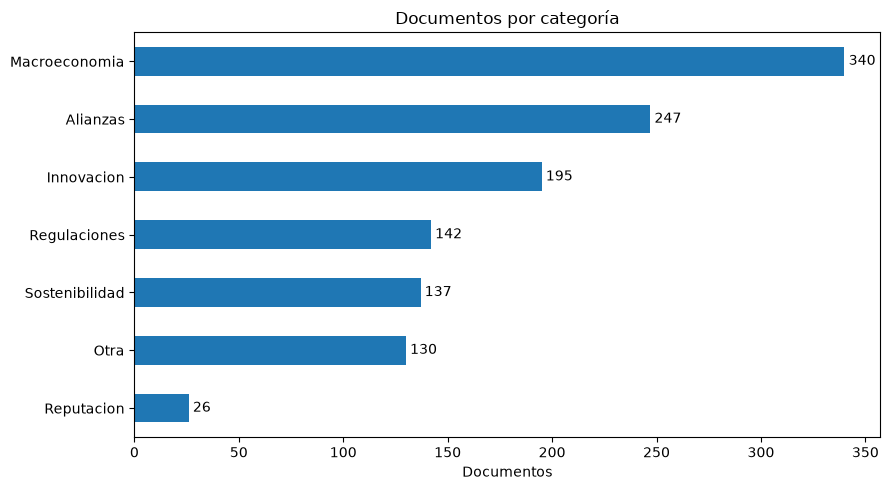

In [47]:
#distribucion de categorias

categorias = (
    df[CATEGORY_COL]
    .fillna("Sin categoría")
    .replace(r"^\s*$", "Sin categoría", regex=True)
)

distribucion = categorias.value_counts().rename_axis("categoria").reset_index(name="documentos")
distribucion["porcentaje"] = distribucion["documentos"].div(len(df)).mul(100)

display(
    distribucion.style
    .hide(axis="index")
    .format({"porcentaje": "{:.2f}%"})
    .set_caption(f"Distribución de {categorias.nunique()} categorías")
)

ax = distribucion.sort_values("documentos").plot.barh(
    x="categoria", y="documentos", legend=False, figsize=(9, 5)
)

ax.bar_label(ax.containers[0], padding=3)
ax.set(title="Documentos por categoría", xlabel="Documentos", ylabel="")
plt.tight_layout()
plt.show()

In [61]:
#filas vacias y duplicadas

columnas_originales = [URL_COL, TEXT_COL, CATEGORY_COL]
datos_originales = df[columnas_originales]

celdas_vacias = (
    datos_originales
    .fillna("")
    .astype(str)
    .apply(lambda columna: columna.str.strip().eq(""))
)

calidad = pd.DataFrame({
    "cantidad": [
        datos_originales.isna().sum().sum(),
        celdas_vacias.any(axis=1).sum(),
        celdas_vacias.all(axis=1).sum(),
        datos_originales.duplicated().sum(),
        datos_originales.duplicated(subset=[TEXT_COL]).sum(),
        datos_originales.duplicated(subset=[URL_COL]).sum()
    ]
}, index=[
    "valores nulos",
    "filas con algun campo vacio",
    "filas completamente vacias",
    "filas completamente duplicadas",
    "noticias duplicadas",
    "URL duplicadas"
])

display(
    calidad.style
    .set_caption("Calidad del corpus")
    .background_gradient(cmap="Oranges")
)

,cantidad
valores nulos,0
filas con algun campo vacio,4
filas completamente vacias,0
filas completamente duplicadas,75
noticias duplicadas,79
URL duplicadas,116


## Preparacion y recursos

In [49]:
#preparamos el corpus para el procesamiento

corpus = df[[URL_COL, TEXT_COL, CATEGORY_COL]].copy()

corpus[TEXT_COL] = corpus[TEXT_COL].fillna("").astype(str)
corpus = corpus[corpus[TEXT_COL].str.strip().ne("")]
corpus = corpus.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

stopwords_es = set(stopwords.words("spanish"))

#basicamente quitamos la puntuacion de los tokens, para que no afecte el conteo de palabras y tipos de palabras

def quitar_puntuacion(token):
    return "".join(
        caracter for caracter in token
        if not unicodedata.category(caracter).startswith("P")
    ).strip()

def contar_tokens_tipos(columna):
    tokens = [token for documento in columna for token in documento]
    return len(tokens), len(set(tokens))

print("Documentos que serán procesados:", len(corpus))

Documentos que serán procesados: 1137


In [50]:
#tokenizacion

tqdm.pandas(desc="Tokenizando")

corpus["tokens_tokenizados"] = corpus[TEXT_COL].progress_apply(
    lambda texto: word_tokenize(texto, language="spanish")
)

#minusculas

corpus["tokens_minusculas"] = corpus["tokens_tokenizados"].apply(
    lambda tokens: [token.lower() for token in tokens]
)

#eliminacion de puntuacion

corpus["tokens_sin_puntuacion"] = corpus["tokens_minusculas"].apply(
    lambda tokens: [
        limpio for token in tokens
        if (limpio := quitar_puntuacion(token))
    ]
)

#eliminacion de stopwords

corpus["tokens_sin_stopwords"] = corpus["tokens_sin_puntuacion"].apply(
    lambda tokens: [token for token in tokens if token not in stopwords_es]
)

Tokenizando: 100%|██████████| 1137/1137 [00:04<00:00, 239.23it/s]


In [60]:
#lematizacion
nlp = spacy.load(
    "es_core_news_sm",
    disable=["parser", "ner"]
)
textos = corpus["tokens_sin_stopwords"].apply(" ".join)
corpus["tokens_lematizados"] = [
    [
        token.lemma_.lower()
        for token in documento
        if token.lemma_.strip()
    ]
    for documento in tqdm(
        nlp.pipe(textos, batch_size=64),
        total=len(textos),
        desc="Lematizando"
    )
]
#tokens y tipos despues de cada etapa
etapas = {
    "Tokenización": "tokens_tokenizados",
    "Minúsculas": "tokens_minusculas",
    "Sin puntuación": "tokens_sin_puntuacion",
    "Sin stopwords": "tokens_sin_stopwords",
    "Lematización": "tokens_lematizados"
}
resultados = []
for etapa, columna in etapas.items():
    tokens, tipos = contar_tokens_tipos(corpus[columna])

    resultados.append({
        "etapa": etapa,
        "tokens": tokens,
        "tipos": tipos
    })

resumen_etapas = pd.DataFrame(resultados)
resumen_etapas["cambio_tokens"] = (
    resumen_etapas["tokens"].diff()
)
resumen_etapas["reduccion_vocabulario_%"] = (
    resumen_etapas["tipos"]
    .pct_change()
    .mul(-100)
    .round(2)
)
display(
    resumen_etapas.style
    .hide(axis="index")
    .set_caption("Tokens y tipos después de cada etapa")
)
#cambio producido durante la lematizacion
tokens_antes_lematizar = resumen_etapas.loc[
    resumen_etapas["etapa"] == "Sin stopwords",
    "tokens"
].iloc[0]

tokens_despues_lematizar = resumen_etapas.loc[
    resumen_etapas["etapa"] == "Lematización",
    "tokens"
].iloc[0]
diferencia_lematizacion = (
    tokens_despues_lematizar - tokens_antes_lematizar
)
if diferencia_lematizacion > 0:
    print(
        f"La lematización produjo un aumento de "
        f"{diferencia_lematizacion:,} tokens."
    )
elif diferencia_lematizacion < 0:
    print(
        f"La lematización produjo una reducción de "
        f"{abs(diferencia_lematizacion):,} tokens."
    )
else:
    print("La lematización no cambió la cantidad de tokens.")

Lematizando: 100%|██████████| 1137/1137 [00:14<00:00, 80.65it/s]


etapa,tokens,tipos,cambio_tokens,reduccion_vocabulario_%
Tokenización,631733,38947,nan,nan
Minúsculas,631733,36099,0.000000,7.310000
Sin puntuación,598600,35460,-33133.000000,1.770000
Sin stopwords,319034,35248,-279566.000000,0.600000
Lematización,319318,28292,284.000000,19.730000


La lematización produjo un aumento de 284 tokens.


### Conclusiones de la exploración inicial

* El corpus contiene **1,217 documentos** y **tres columnas**.
* url guarda el enlace original, news contiene el texto de la noticia y Type indica su categoría.
* Se encontraron **7 categorías**, cuya distribución se muestra en la tabla y gráfica anteriores.
* Se identificaron **4 filas con campos vacíos**, **0 filas completamente vacías** y **79 noticias duplicadas**.

In [52]:
#tokens y tipos antes y despues de normalizar
tokens_antes = [
    token
    for documento in corpus["tokens_tokenizados"]
    for token in documento
]

tokens_normalizados = [
    token
    for documento in corpus["tokens_lematizados"]
    for token in documento
]

comparacion_vocabulario = pd.DataFrame({
    "etapa": ["Antes de normalizar", "Después de normalizar"],
    "tokens": [len(tokens_antes), len(tokens_normalizados)],
    "tipos": [len(set(tokens_antes)), len(set(tokens_normalizados))]
})

reduccion_vocabulario = (
    1 - comparacion_vocabulario.loc[1, "tipos"]
    / comparacion_vocabulario.loc[0, "tipos"]
) * 100
display(comparacion_vocabulario)
print(f"Reducción del vocabulario: {reduccion_vocabulario:.2f}%")

,etapa,tokens,tipos
0,Antes de normalizar,631733,38947
1,Después de normalizar,319318,28292


Reducción del vocabulario: 27.36%


In [53]:
#riqueza lexica global y por categoria
def calcular_riqueza(documentos):
    tokens = [token for documento in documentos for token in documento]
    return len(set(tokens)) / len(tokens) if tokens else 0
riqueza_global = calcular_riqueza(corpus["tokens_lematizados"])
riqueza_categoria = (
    corpus.groupby(CATEGORY_COL)["tokens_lematizados"]
    .apply(calcular_riqueza)
    .sort_values(ascending=False)
    .rename("riqueza_lexica")
    .to_frame()
)
print(f"Riqueza léxica global: {riqueza_global:.4f}")
display(riqueza_categoria.style.format("{:.4f}"))

Riqueza léxica global: 0.0886


,riqueza_lexica
Type,
Reputacion,0.3503
Regulaciones,0.2152
Otra,0.2044
Alianzas,0.2028
Sostenibilidad,0.1536
Innovacion,0.1377
Macroeconomia,0.1250


In [54]:
#20 palabras mas frecuentes del corpus normalizado

frecuencias_normalizadas = Counter(tokens_normalizados)

top_20 = pd.DataFrame(
    frecuencias_normalizadas.most_common(20),
    columns=["palabra", "frecuencia"]
)

display(
    top_20.style
    .hide(axis="index")
    .set_caption("20 palabras más frecuentes del corpus normalizado")
)

palabra,frecuencia
poder,2398
bbva,2149
año,2024
banco,1463
país,1398
inflación,1349
empresa,1294
nuevo,1215
precio,1199
ser,1192


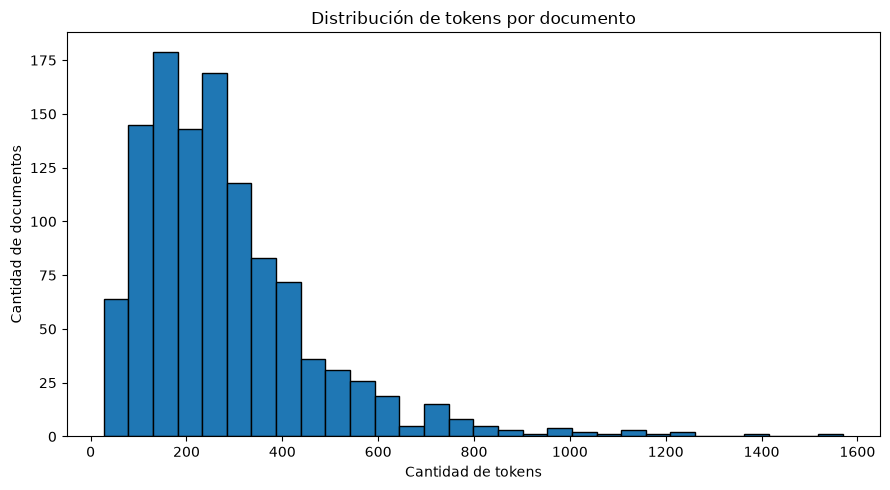

count    1137.00
mean      280.84
std       187.61
min        27.00
25%       150.00
50%       245.00
75%       354.00
max      1570.00
Name: tokens_lematizados, dtype: float64


In [55]:
#distribucion de tokens por documento
tokens_por_documento = corpus["tokens_lematizados"].str.len()
plt.figure(figsize=(9, 5))
plt.hist(tokens_por_documento, bins=30, edgecolor="black")
plt.title("Distribución de tokens por documento")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Cantidad de documentos")
plt.tight_layout()
plt.show()
print(tokens_por_documento.describe().round(2))

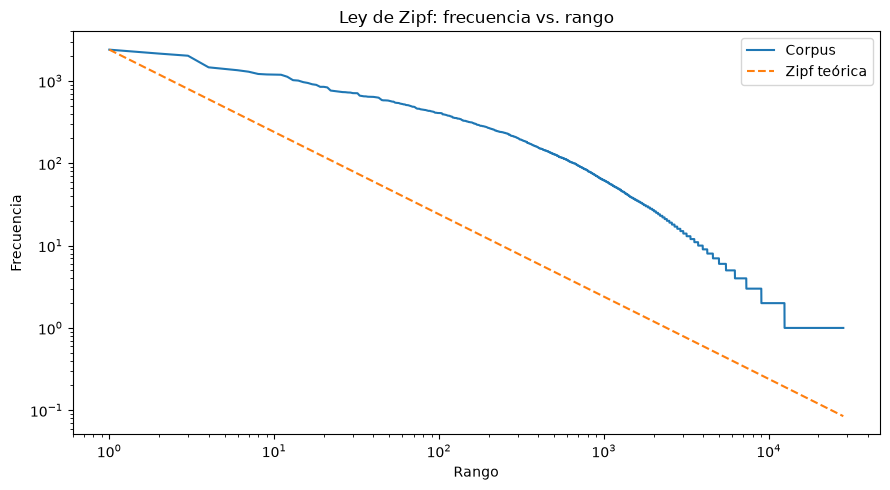

Pendiente teórica de Zipf: -1.000
Pendiente observada: -1.262
R² del ajuste logarítmico: 0.954
La curva conserva la forma descendente de Zipf, pero la frecuencia disminuye más rápidamente que en la curva teórica.


In [62]:
#ley de Zipf

frecuencias_ordenadas = np.array(
    sorted(frecuencias_normalizadas.values(), reverse=True)
)

rangos = np.arange(1, len(frecuencias_ordenadas) + 1)
zipf_teorica = frecuencias_ordenadas[0] / rangos

plt.figure(figsize=(9, 5))
plt.loglog(rangos, frecuencias_ordenadas, label="Corpus")
plt.loglog(rangos, zipf_teorica, "--", label="Zipf teórica")

plt.title("Ley de Zipf: frecuencia vs. rango")
plt.xlabel("Rango")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

#ajuste lineal en escala logaritmica

log_rangos = np.log10(rangos)
log_frecuencias = np.log10(frecuencias_ordenadas)

pendiente, intercepto = np.polyfit(
    log_rangos,
    log_frecuencias,
    1
)

frecuencias_estimadas = (
    pendiente * log_rangos + intercepto
)

r_cuadrado = 1 - (
    np.sum((log_frecuencias - frecuencias_estimadas) ** 2)
    / np.sum((log_frecuencias - log_frecuencias.mean()) ** 2)
)

print("Pendiente teórica de Zipf: -1.000")
print(f"Pendiente observada: {pendiente:.3f}")
print(f"R² del ajuste logarítmico: {r_cuadrado:.3f}")

if abs(pendiente + 1) <= 0.15:
    print(
        "La curva del corpus se aproxima a la curva teórica de Zipf, "
        "porque su pendiente es cercana a -1."
    )
elif pendiente < -1:
    print(
        "La curva conserva la forma descendente de Zipf, pero la frecuencia "
        "disminuye más rápidamente que en la curva teórica."
    )
else:
    print(
        "La curva conserva la forma descendente de Zipf, pero la frecuencia "
        "disminuye más lentamente que en la curva teórica."
    )

In [57]:
#comparacion de las dos categorias con mas documentos

categorias_comparar = (
    corpus[CATEGORY_COL]
    .value_counts()
    .head(2)
    .index
    .tolist()
)

resultados_categoria = {}

for categoria in categorias_comparar:
    documentos = corpus.loc[
        corpus[CATEGORY_COL] == categoria,
        "tokens_lematizados"
    ]

    tokens = [
        token
        for documento in documentos
        for token in documento
    ]

    resultados_categoria[categoria] = Counter(tokens).most_common(10)

categoria_1, categoria_2 = categorias_comparar

comparacion_categorias = pd.DataFrame({
    f"{categoria_1} - palabra":
        [palabra for palabra, _ in resultados_categoria[categoria_1]],

    f"{categoria_1} - frecuencia":
        [frecuencia for _, frecuencia in resultados_categoria[categoria_1]],

    f"{categoria_2} - palabra":
        [palabra for palabra, _ in resultados_categoria[categoria_2]],

    f"{categoria_2} - frecuencia":
        [frecuencia for _, frecuencia in resultados_categoria[categoria_2]]
})

display(comparacion_categorias)

palabras_1 = {palabra for palabra, _ in resultados_categoria[categoria_1]}
palabras_2 = {palabra for palabra, _ in resultados_categoria[categoria_2]}

print("Palabras compartidas:", ", ".join(sorted(palabras_1 & palabras_2)))
print(f"Exclusivas de {categoria_1}:", ", ".join(sorted(palabras_1 - palabras_2)))
print(f"Exclusivas de {categoria_2}:", ", ".join(sorted(palabras_2 - palabras_1)))

,Macroeconomia - palabra,Macroeconomia - frecuencia,Alianzas - palabra,Alianzas - frecuencia
0,inflación,1279,alianza,424
1,precio,986,poder,337
2,año,905,país,330
3,poder,666,nuevo,254
4,tasa,512,colombia,254
5,mayor,507,millón,245
6,bbva,494,año,244
7,mes,490,empresa,234
8,país,431,hacer,199
9,aumento,416,mercado,184


Palabras compartidas: año, país, poder
Exclusivas de Macroeconomia: aumento, bbva, inflación, mayor, mes, precio, tasa
Exclusivas de Alianzas: alianza, colombia, empresa, hacer, mercado, millón, nuevo


*En la categoria "macroeconomia" predominan terminos como inflacion, precio, tasa, etc. Lo que refleja que als noticias, naturalmente, estan orientadas al comportamiento de precios e indicadores economicos. Por otro lado, en alianzas, las palabras mas frecuentes incluyen alianza, empresa, mercado, etc. Esto sugiere contenidos enfocados en acuerdos comercionales o al ambito empresarial en general. Aunque ambas categorias comparten tambien algunos terminos como pais y poder. Sin embargo, sus palabras muestran con claridad temas distintos.*

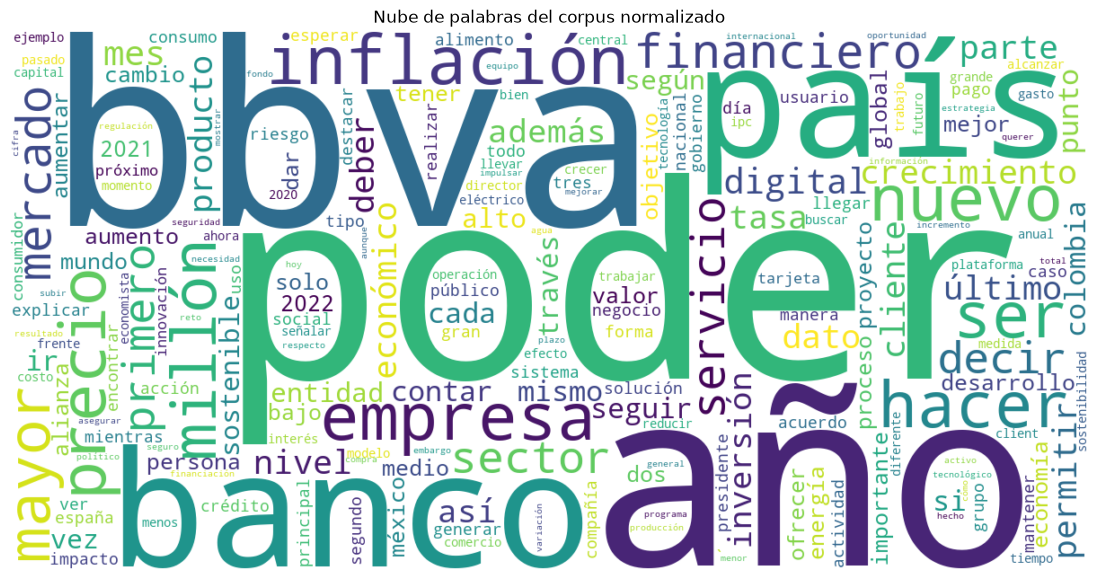

In [58]:
#nube de palabras del corpus normalizado
nube = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis"
).generate_from_frequencies(frecuencias_normalizadas)
plt.figure(figsize=(14, 7))
plt.imshow(nube, interpolation="bilinear")
plt.axis("off")
plt.title("Nube de palabras del corpus normalizado")
plt.show()